In [1]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Project directory
BASE_DIR = Path.cwd()

if not (BASE_DIR / "data").exists():
    BASE_DIR = BASE_DIR.parent

# Load datasets
jobs = pd.read_csv(
    BASE_DIR / "data" / "processed" / "cleaned_jobs.csv"
)

resumes = pd.read_csv(
    BASE_DIR / "data" / "processed" / "cleaned_resumes.csv"
)

print("SMART HIRE - DATASET ANALYSIS")
print("=" * 40)

print("\nJob dataset shape:", jobs.shape)
print("Job columns:", jobs.columns.tolist())

print("\nResume dataset shape:", resumes.shape)
print("Resume columns:", resumes.columns.tolist())

print("\nResume category distribution:")
print(resumes["Category"].value_counts())

display(jobs.head())
display(resumes.head())


SMART HIRE - DATASET ANALYSIS

Job dataset shape: (119155, 4)
Job columns: ['title', 'description', 'company_name', 'location']

Resume dataset shape: (166, 2)
Resume columns: ['Category', 'Resume']

Resume category distribution:
Category
Java Developer               13
Database                     11
Data Science                 10
HR                           10
Advocate                     10
Automation Testing            7
DevOps Engineer               7
Hadoop                        7
DotNet Developer              7
Testing                       7
Arts                          6
Health and fitness            6
Civil Engineer                6
Business Analyst              6
SAP Developer                 6
Python Developer              6
Mechanical Engineer           5
Sales                         5
Electrical Engineering        5
Network Security Engineer     5
ETL Developer                 5
Blockchain                    5
Web Designing                 4
Operations Manager       

,title,description,company_name,location
0,Marketing Coordinator,Job descriptionA leading real estate firm in N...,Corcoran Sawyer Smith,"Princeton, NJ"
1,Mental Health Therapist/Counselor,"At Aspen Therapy and Wellness , we are committ...",Not specified,"Fort Collins, CO"
2,Assitant Restaurant Manager,The National Exemplar is accepting application...,The National Exemplar,"Cincinnati, OH"
3,Senior Elder Law / Trusts and Estates Associat...,Senior Associate Attorney - Elder Law / Trusts...,"Abrams Fensterman, LLP","New Hyde Park, NY"
4,Service Technician,Looking for HVAC service tech with experience ...,Not specified,"Burlington, IA"


,Category,Resume
0,Data Science,skills programming languages python pandas num...
1,Data Science,education details may 2013 to may 2017 b.e uit...
2,Data Science,areas of interest deep learning control system...
3,Data Science,skills r python sap hana tableau sap hana sql ...
4,Data Science,education details mca ymcaust faridabad haryan...


Number of unique resume categories: 25

Resumes in each category:
Category
Java Developer               13
Database                     11
Data Science                 10
HR                           10
Advocate                     10
Automation Testing            7
DevOps Engineer               7
Hadoop                        7
DotNet Developer              7
Testing                       7
Arts                          6
Health and fitness            6
Civil Engineer                6
Business Analyst              6
SAP Developer                 6
Python Developer              6
Mechanical Engineer           5
Sales                         5
Electrical Engineering        5
Network Security Engineer     5
ETL Developer                 5
Blockchain                    5
Web Designing                 4
Operations Manager            4
PMO                           3
Name: count, dtype: int64


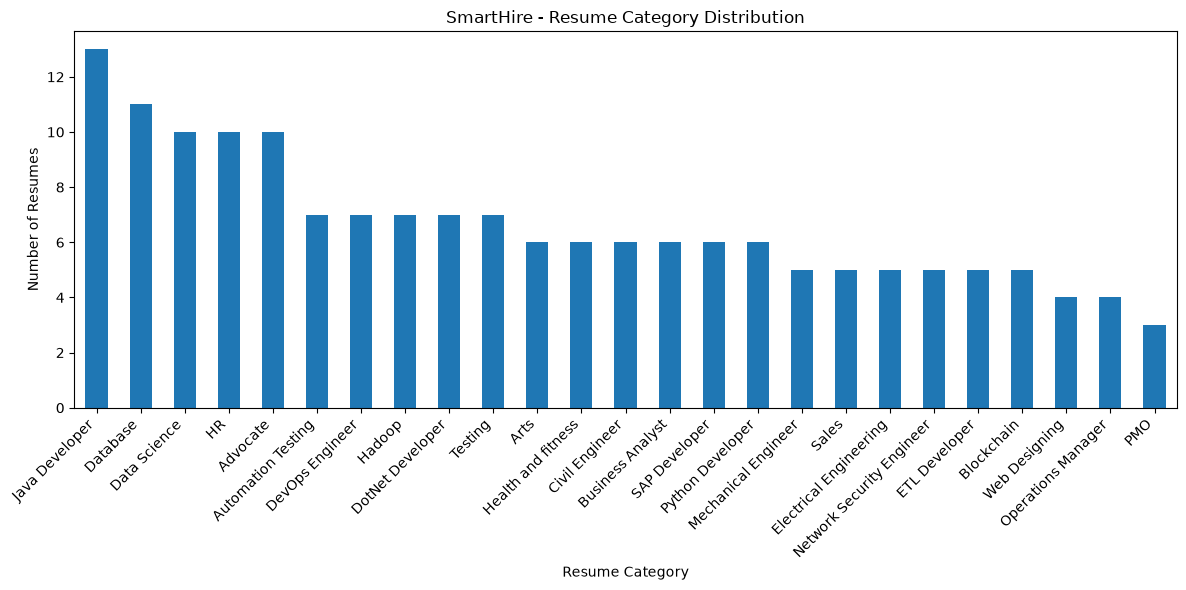

In [2]:

# Analyze the distribution of resume categories

category_counts = resumes["Category"].value_counts()

print("Number of unique resume categories:", len(category_counts))
print("\nResumes in each category:")
print(category_counts)

# Plot the category distribution
plt.figure(figsize=(12, 6))

category_counts.plot(kind="bar")

plt.title("SmartHire - Resume Category Distribution")
plt.xlabel("Resume Category")
plt.ylabel("Number of Resumes")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()


Total unique job titles: 72101

Top 15 job titles:
title
Sales Manager                      438
Project Manager                    357
Customer Service Representative    354
Administrative Assistant           253
Senior Accountant                  241
Salesperson                        204
Registered Nurse                   204
Staff Accountant                   201
Receptionist                       196
Executive Assistant                193
Account Executive                  193
Retail Sales Associate             183
Software Engineer                  181
Sales Associate                    174
Controller                         173
Name: count, dtype: int64


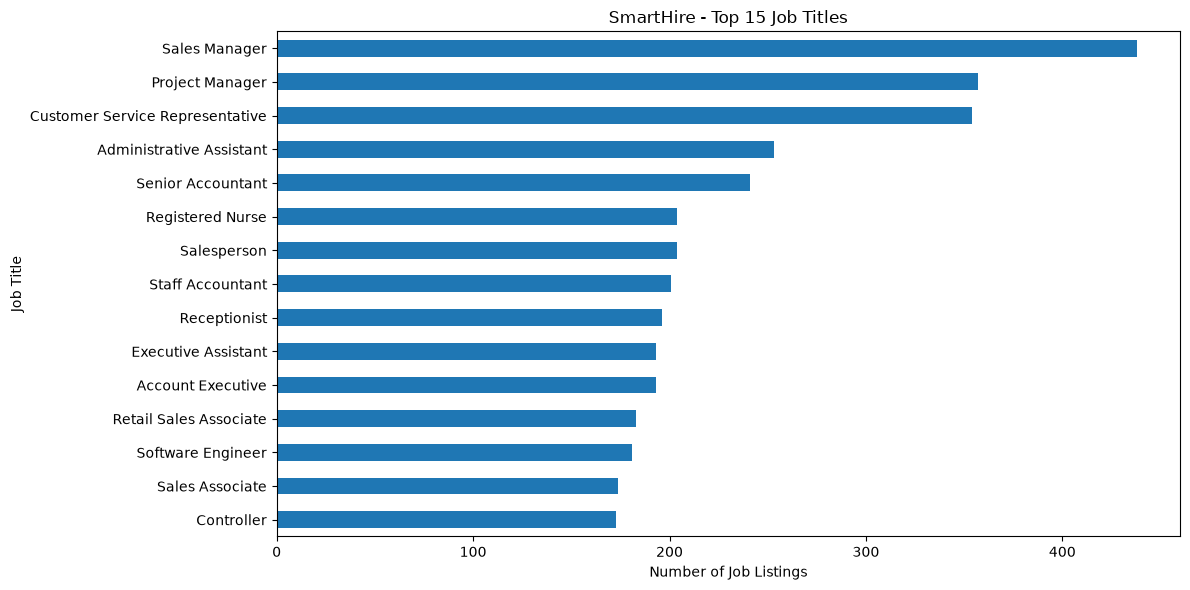

In [3]:

# Analyze the most common job titles

top_jobs = jobs["title"].value_counts().head(15)

print("Total unique job titles:", jobs["title"].nunique())
print("\nTop 15 job titles:")
print(top_jobs)

plt.figure(figsize=(12, 6))
top_jobs.sort_values().plot(kind="barh")

plt.title("SmartHire - Top 15 Job Titles")
plt.xlabel("Number of Job Listings")
plt.ylabel("Job Title")
plt.tight_layout()
plt.show()


Number of unique job locations: 8526

Top 15 job locations:
location
United States                      7822
New York, NY                       2698
Chicago, IL                        1801
Houston, TX                        1680
Dallas, TX                         1340
Atlanta, GA                        1334
Boston, MA                         1117
Austin, TX                         1055
Charlotte, NC                      1032
Phoenix, AZ                        1016
Los Angeles, CA                     951
San Francisco, CA                   859
Washington, DC                      851
New York City Metropolitan Area     817
Seattle, WA                         800
Name: count, dtype: int64


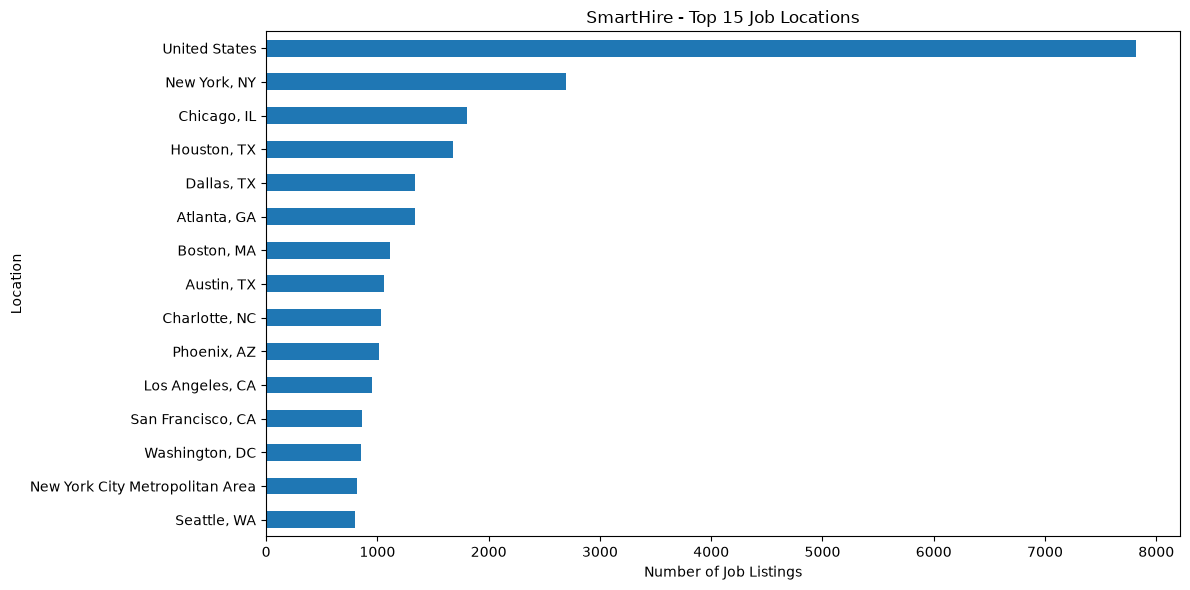

In [4]:

# Find the locations with the most job listings

top_locations = jobs["location"].value_counts().head(15)

print("Number of unique job locations:", jobs["location"].nunique())
print("\nTop 15 job locations:")
print(top_locations)

plt.figure(figsize=(12, 6))
top_locations.sort_values().plot(kind="barh")

plt.title("SmartHire - Top 15 Job Locations")
plt.xlabel("Number of Job Listings")
plt.ylabel("Location")
plt.tight_layout()
plt.show()


In [11]:
# ============================================================
# SmartHire - Resume Classification and Model Evaluation
# ============================================================

from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

# ------------------------------------------------------------
# 1. Locate the project folder
# ------------------------------------------------------------

current_dir = Path.cwd().resolve()

if current_dir.name.lower() == "notebooks":
    PROJECT_DIR = current_dir.parent
else:
    PROJECT_DIR = current_dir

print("Project directory:", PROJECT_DIR)

# ------------------------------------------------------------
# 2. Find the resume dataset
# ------------------------------------------------------------

possible_paths = [
    PROJECT_DIR / "data" / "UpdatedResumeDataSet.csv",
    PROJECT_DIR / "data" / "raw" / "UpdatedResumeDataSet.csv",
]

DATA_PATH = next(
    (path for path in possible_paths if path.is_file()),
    None
)

if DATA_PATH is None:
    print("\nCSV files found in the data folder:")

    data_dir = PROJECT_DIR / "data"

    if data_dir.exists():
        for path in data_dir.rglob("*.csv"):
            print(path)
    else:
        print("Data folder does not exist:", data_dir)

    raise FileNotFoundError(
        "UpdatedResumeDataSet.csv was not found. "
        "Check the CSV filenames printed above."
    )

print("Dataset path:", DATA_PATH)

# ------------------------------------------------------------
# 3. Load the dataset
# ------------------------------------------------------------

df = pd.read_csv(DATA_PATH)

print("\nDataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

# ------------------------------------------------------------
# 4. Validate required columns
# ------------------------------------------------------------

required_columns = ["Resume", "Category"]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}. "
        f"Available columns: {df.columns.tolist()}"
    )

# ------------------------------------------------------------
# 5. Clean the data
# ------------------------------------------------------------

df = df[["Resume", "Category"]].copy()

df["Resume"] = df["Resume"].fillna("").astype(str).str.strip()
df["Category"] = df["Category"].fillna("").astype(str).str.strip()

# Remove empty resume text and category labels
df = df[
    (df["Resume"] != "") &
    (df["Category"] != "")
].copy()

# Remove exact duplicate records
df = df.drop_duplicates(subset=["Resume", "Category"])

print("\nDataset after cleaning:")
print("Total resumes:", len(df))
print("Total categories:", df["Category"].nunique())

print("\nResumes per category:")
display(df["Category"].value_counts())

# ------------------------------------------------------------
# 6. Prepare input features and target labels
# ------------------------------------------------------------

X = df["Resume"]
y = df["Category"]

if y.nunique() < 2:
    raise ValueError(
        "At least two different categories are required "
        "to train a classifier."
    )

# Stratification preserves category proportions where possible.
# It requires at least two examples in every category.

category_counts = y.value_counts()

if category_counts.min() >= 2:
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )
else:
    print(
        "\nWarning: Some categories contain fewer than "
        "two resumes. Using a non-stratified split."
    )

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42
    )

print("\nTraining resumes:", len(X_train))
print("Testing resumes:", len(X_test))

# ------------------------------------------------------------
# 7. Build the machine learning pipeline
# ------------------------------------------------------------

model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            stop_words="english",
            max_features=5000,
            ngram_range=(1, 2),
            sublinear_tf=True
        )
    )
])   

Project directory: C:\Users\ASUS\OneDrive\Documents\smart_hire
Dataset path: C:\Users\ASUS\OneDrive\Documents\smart_hire\data\raw\UpdatedResumeDataSet.csv

Dataset loaded successfully!
Dataset shape: (962, 2)
Column names: ['Category', 'Resume']

First five rows:


,Category,Resume
0,Data Science,Skills * Programming Languages: Python (pandas...
1,Data Science,Education Details \r\nMay 2013 to May 2017 B.E...
2,Data Science,"Areas of Interest Deep Learning, Control Syste..."
3,Data Science,Skills â¢ R â¢ Python â¢ SAP HANA â¢ Table...
4,Data Science,"Education Details \r\n MCA YMCAUST, Faridab..."



Dataset after cleaning:
Total resumes: 166
Total categories: 25

Resumes per category:


Category
Java Developer               13
Database                     11
Data Science                 10
HR                           10
Advocate                     10
Automation Testing            7
DevOps Engineer               7
Hadoop                        7
DotNet Developer              7
Testing                       7
Arts                          6
Health and fitness            6
Civil Engineer                6
Business Analyst              6
SAP Developer                 6
Python Developer              6
Mechanical Engineer           5
Sales                         5
Electrical Engineering        5
Network Security Engineer     5
ETL Developer                 5
Blockchain                    5
Web Designing                 4
Operations Manager            4
PMO                           3
Name: count, dtype: int64


Training resumes: 132
Testing resumes: 34


Training the SmartHire model...
Training completed successfully!

Model Accuracy: 85.29%

Classification Report:
                           precision    recall  f1-score   support

                 Advocate       1.00      1.00      1.00         2
                     Arts       1.00      1.00      1.00         1
       Automation Testing       0.33      1.00      0.50         1
               Blockchain       1.00      1.00      1.00         1
         Business Analyst       1.00      1.00      1.00         1
           Civil Engineer       1.00      1.00      1.00         1
             Data Science       1.00      1.00      1.00         2
                 Database       1.00      1.00      1.00         2
          DevOps Engineer       0.00      0.00      0.00         1
         DotNet Developer       1.00      1.00      1.00         2
            ETL Developer       1.00      1.00      1.00         1
   Electrical Engineering       1.00      1.00      1.00         1
               

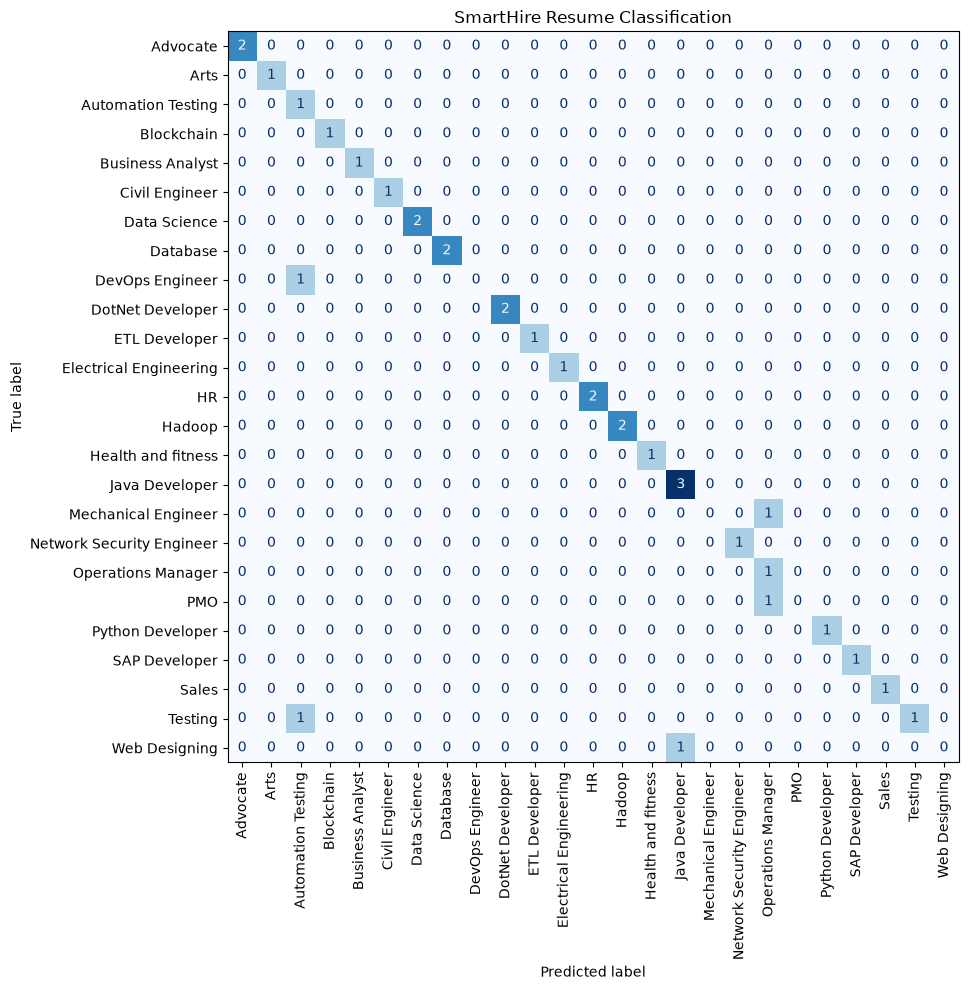


Model saved at: c:\Users\ASUS\OneDrive\Documents\smart_hire\models\resume_classifier_eda.pkl


In [13]:

# SmartHire: Train and evaluate resume classifier

import joblib
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

# Create the classifier pipeline
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        stop_words="english",
        max_features=5000
    )),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train the model
print("Training the SmartHire model...")
model.fit(X_train, y_train)
print("Training completed successfully!")

# Make predictions
y_pred = model.predict(X_test)

# Evaluate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"\nModel Accuracy: {accuracy * 100:.2f}%")

# Display classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

# Display confusion matrix
fig, ax = plt.subplots(figsize=(14, 10))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=model.classes_,
    xticks_rotation="vertical",
    cmap="Blues",
    colorbar=False,
    ax=ax
)

ax.set_title("SmartHire Resume Classification")
plt.tight_layout()
plt.show()

# Save the trained model
PROJECT_DIR = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODEL_DIR / "resume_classifier_eda.pkl"
joblib.dump(model, MODEL_PATH)

print(f"\nModel saved at: {MODEL_PATH}")
